# Perbandingan K-Means vs DBSCAN vs HDBSCAN

Notebook ini membandingkan **3 algoritma x 3 metrik jarak (Euclidean, Manhattan, Cosine) = 9 hasil** pada data yang sama (Diabetes health indicators, 63.197 baris x 15 fitur).

Notebook ini **tidak menjalankan ulang klastering**. Ia hanya membaca file `evaluasi_*.xlsx` yang sudah dihasilkan notebook K-Means, DBSCAN, dan HDBSCAN, lalu menyatukannya jadi tabel dan grafik.

Catatan supaya perbandingannya adil:
- K-Means tidak punya noise (semua titik masuk klaster), sedangkan DBSCAN dan HDBSCAN membuang titik noise. Metrik kualitas DBSCAN/HDBSCAN dihitung hanya pada titik **non-noise**, jadi angkanya terlihat bagus tapi hanya mewakili sebagian data. Karena itu ada kolom **Data Terklaster (%)**.
- Silhouette HDBSCAN dihitung pada sampel 10.000 titik non-noise.
- HDBSCAN Cosine dijalankan dengan jarak Euclidean pada data yang sudah distandarisasi, lalu dievaluasi dengan jarak Cosine. Jadi bukan HDBSCAN dengan jarak Cosine murni.
- Waktu eksekusi bergantung mesin (Colab vs Kaggle), jadi hanya bisa dibaca sebagai perkiraan kasar.


In [ ]:
# import library & lokasi file hasil
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import warnings
from collections import Counter

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# --- lokasi kerja: Colab (Drive). Di tempat lain, ubah BASE ke folder ml-sem5 kamu ---
BASE = os.environ.get('ML_SEM5_BASE', "/content/drive/MyDrive/ml-semester5")
if not os.path.exists(BASE):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass

DIR_KMEANS  = os.path.join(BASE, "kuis1", "outputKmeans")
DIR_DBSCAN  = os.path.join(BASE, "kuis1", "outputDBSCAN")
DIR_HDBSCAN = os.path.join(BASE, "HDBSCAN", "outputHDBSCAN")
OUTPUT_DIR  = os.path.join(BASE, "HDBSCAN", "outputPerbandingan")
os.makedirs(OUTPUT_DIR, exist_ok=True)

METRIK = ['Euclidean', 'Manhattan', 'Cosine']
ALGO   = ['K-Means', 'DBSCAN', 'HDBSCAN']

FILES = []
for m in METRIK:
    FILES.append(('K-Means', m, os.path.join(DIR_KMEANS,  f'evaluasi_kmeans_{m.lower()}.xlsx')))
for m in METRIK:
    FILES.append(('DBSCAN',  m, os.path.join(DIR_DBSCAN,  f'evaluasi_dbscan_{m.lower()}.xlsx')))
for m in METRIK:
    FILES.append(('HDBSCAN', m, os.path.join(DIR_HDBSCAN, f'evaluasi_hdbscan_{m.lower()}.xlsx')))

# Cek file yang sudah ada
for algo, metrik, path in FILES:
    status = "ADA" if os.path.exists(path) else "BELUM ADA"
    print(f"[{status}] {algo:8s} {metrik:10s} -> {path}")


Mounted at /content/drive
[ADA] K-Means  Euclidean  -> /content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/evaluasi_kmeans_euclidean.xlsx
[ADA] K-Means  Manhattan  -> /content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/evaluasi_kmeans_manhattan.xlsx
[ADA] K-Means  Cosine     -> /content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/evaluasi_kmeans_cosine.xlsx
[ADA] DBSCAN   Euclidean  -> /content/drive/MyDrive/ml-sem5/kuis1/outputDBSCAN/evaluasi_dbscan_euclidean.xlsx
[ADA] DBSCAN   Manhattan  -> /content/drive/MyDrive/ml-sem5/kuis1/outputDBSCAN/evaluasi_dbscan_manhattan.xlsx
[ADA] DBSCAN   Cosine     -> /content/drive/MyDrive/ml-sem5/kuis1/outputDBSCAN/evaluasi_dbscan_cosine.xlsx
[ADA] HDBSCAN  Euclidean  -> /content/drive/MyDrive/ml-sem5/HDBSCAN/outputHDBSCAN/evaluasi_hdbscan_euclidean.xlsx
[ADA] HDBSCAN  Manhattan  -> /content/drive/MyDrive/ml-sem5/HDBSCAN/outputHDBSCAN/evaluasi_hdbscan_manhattan.xlsx
[ADA] HDBSCAN  Cosine     -> /content/drive/MyDrive/ml-sem5/HDBSCAN/outputHDBSCAN/evaluasi_h

In [ ]:
# baca & samakan kolom semua hasil
def ambil(df, awalan):
    # ambil nilai dari kolom yang namanya diawali teks tertentu (nama kolom tiap file sedikit berbeda)
    kolom = [c for c in df.columns if c.startswith(awalan)]
    return df[kolom[0]].iloc[0] if kolom else np.nan

rows = []
for algo, metrik, path in FILES:
    if not os.path.exists(path):
        print(f"[LEWAT] File belum ada: {path}")
        continue
    d = pd.read_excel(path, sheet_name='Ringkasan_Evaluasi')

    if algo == 'K-Means':
        n_klaster = ambil(d, 'Optimal k')
        # Sama seperti notebook perbandingan sebelumnya: k dipaksa 4 untuk Manhattan
        # (Manhattan optimal di 3, sedangkan metrik lain optimal di 4, jadi diambil k mayoritas)
        if metrik == 'Manhattan':
            n_klaster = 4
        parameter = f"k = {int(n_klaster)}"
        noise = 0.0
    elif algo == 'DBSCAN':
        n_klaster = ambil(d, 'Jumlah Klaster')
        parameter = f"eps = {ambil(d, 'eps')}, MinPts = {int(ambil(d, 'MinPts'))}"
        noise = ambil(d, 'Noise (%)')
    else:  # HDBSCAN
        n_klaster = ambil(d, 'Jumlah Klaster')
        parameter = f"min_cluster_size = {int(ambil(d, 'min_cluster_size'))}, min_samples = {int(ambil(d, 'MinPts'))}"
        noise = ambil(d, 'Noise (%)')

    rows.append({
        'Algoritma': algo,
        'Metrik Jarak': metrik,
        'Parameter': parameter,
        'Jumlah Data': ambil(d, 'Jumlah Data'),
        'Jumlah Klaster': n_klaster,
        'Noise (%)': noise,
        'Data Terklaster (%)': round(100 - noise, 2),
        'Silhouette (↑)': ambil(d, 'Silhouette'),
        'Davies–Bouldin (↓)': ambil(d, 'Davies'),
        'Calinski–Harabasz (↑)': ambil(d, 'Calinski'),
        'Waktu Eksekusi (s) (↓)': ambil(d, 'Execution Time'),
    })

perbandingan = pd.DataFrame(rows)
print(f"[INFO] {len(perbandingan)} dari {len(FILES)} hasil berhasil dibaca.")


[INFO] 9 dari 9 hasil berhasil dibaca.


In [ ]:
# tabel perbandingan: 9 hasil dalam satu tabel + tabel per metrik jarak
kolom_tabel = ['Algoritma', 'Parameter', 'Jumlah Klaster', 'Noise (%)', 'Data Terklaster (%)',
               'Silhouette (↑)', 'Davies–Bouldin (↓)', 'Calinski–Harabasz (↑)', 'Waktu Eksekusi (s) (↓)']

tabel_metrik = {}
for m in METRIK:
    sub = perbandingan[perbandingan['Metrik Jarak'] == m][kolom_tabel].reset_index(drop=True)
    tabel_metrik[m] = sub
    print("=" * 140)
    print(f"PERBANDINGAN ALGORITMA - METRIK {m.upper()}")
    print("=" * 140)
    print(sub.to_string(index=False))
    print()

excel_path = os.path.join(OUTPUT_DIR, "perbandingan_3_algoritma.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    perbandingan.to_excel(writer, sheet_name='Gabungan', index=False)
    for m, sub in tabel_metrik.items():
        sub.to_excel(writer, sheet_name=m, index=False)
print(f"[SIMPAN] Tabel perbandingan disimpan ke: '{excel_path}'")


PERBANDINGAN ALGORITMA - METRIK EUCLIDEAN
Algoritma                                Parameter  Jumlah Klaster  Noise (%)  Data Terklaster (%)  Silhouette (↑)  Davies–Bouldin (↓)  Calinski–Harabasz (↑)  Waktu Eksekusi (s) (↓)
  K-Means                                    k = 4               4       0.00               100.00          0.1068              2.3585                7218.13                 0.62206
   DBSCAN                eps = 1.7321, MinPts = 30             207      27.64                72.36          0.2593              1.4483                 697.89                62.79510
  HDBSCAN min_cluster_size = 316, min_samples = 30              45      17.30                82.70          0.0828              1.5936                1312.88               151.10932

PERBANDINGAN ALGORITMA - METRIK MANHATTAN
Algoritma                                Parameter  Jumlah Klaster  Noise (%)  Data Terklaster (%)  Silhouette (↑)  Davies–Bouldin (↓)  Calinski–Harabasz (↑)  Waktu Eksekusi (s) (↓)
  K-M

[SIMPAN] Grafik disimpan ke: '/content/drive/MyDrive/ml-sem5/HDBSCAN/outputPerbandingan/perbandingan_3_algoritma.png'


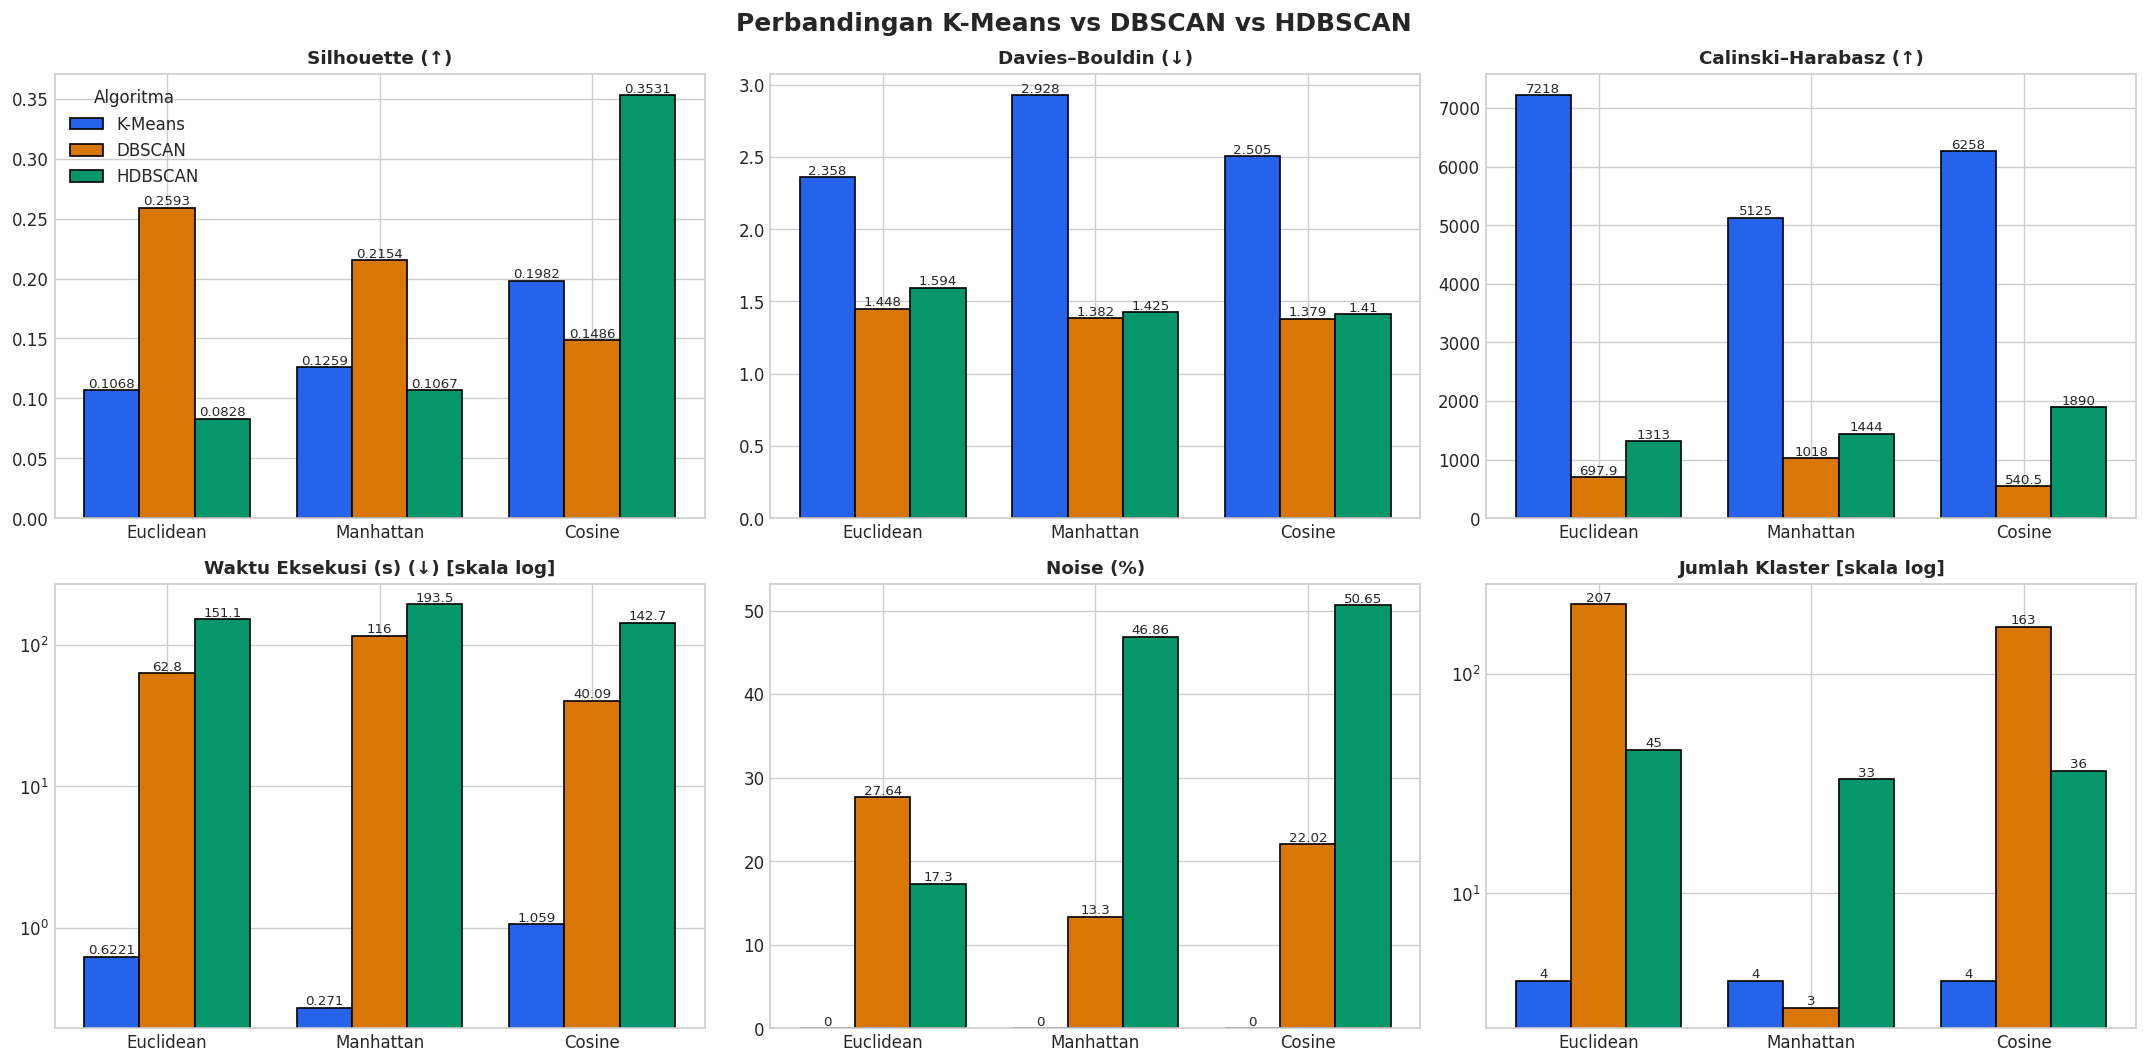

In [ ]:
# grafik perbandingan: tiap panel = satu metrik evaluasi, batang dikelompokkan per metrik jarak
warna_algo = {'K-Means': '#2563EB', 'DBSCAN': '#D97706', 'HDBSCAN': '#059669'}
panels = [
    ('Silhouette (↑)', False),
    ('Davies–Bouldin (↓)', False),
    ('Calinski–Harabasz (↑)', False),
    ('Waktu Eksekusi (s) (↓)', True),   # skala log: K-Means jauh lebih cepat dari yang lain
    ('Noise (%)', False),
    ('Jumlah Klaster', True),           # skala log: DBSCAN/HDBSCAN bisa ratusan klaster
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()
lebar = 0.26
x = np.arange(len(METRIK))
for ax, (kolom, pakai_log) in zip(axes, panels):
    for i, algo in enumerate(ALGO):
        vals = []
        for m in METRIK:
            s = perbandingan[(perbandingan['Algoritma'] == algo) & (perbandingan['Metrik Jarak'] == m)][kolom]
            vals.append(s.iloc[0] if len(s) else np.nan)
        pos = x + (i - 1) * lebar
        ax.bar(pos, vals, width=lebar, color=warna_algo[algo], edgecolor='black', label=algo)
        for p, v in zip(pos, vals):
            if not np.isnan(v):
                ax.text(p, v, f'{v:.4g}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(METRIK)
    ax.set_title(kolom + (' [skala log]' if pakai_log else ''), fontsize=11, fontweight='bold')
    if pakai_log:
        ax.set_yscale('log')
axes[0].legend(title='Algoritma')
plt.suptitle('Perbandingan K-Means vs DBSCAN vs HDBSCAN', fontsize=15, fontweight='bold')
plt.tight_layout()
path = os.path.join(OUTPUT_DIR, "perbandingan_3_algoritma.png")
plt.savefig(path, dpi=300)
print(f"[SIMPAN] Grafik disimpan ke: '{path}'")
plt.show()


In [ ]:
# galeri PCA 2D: per metrik jarak, tiga algoritma berdampingan (memakai gambar yang sudah tersimpan)
for m in METRIK:
    items = [
        ('K-Means', os.path.join(DIR_KMEANS,  f'cluster_{m.lower()}.png')),
        ('DBSCAN',  os.path.join(DIR_DBSCAN,  f'cluster_dbscan_{m.lower()}.png')),
        ('HDBSCAN', os.path.join(DIR_HDBSCAN, f'cluster_hdbscan_{m.lower()}.png')),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(24, 7))
    for ax, (nama, p) in zip(axes, items):
        if os.path.exists(p):
            ax.imshow(mpimg.imread(p))
            ax.set_title(f'{nama} - {m}', fontsize=13, fontweight='bold')
        else:
            ax.text(0.5, 0.5, f'Gambar belum ada:\n{os.path.basename(p)}', ha='center', va='center')
        ax.axis('off')
    plt.suptitle(f'Pemetaan Klaster PCA 2D - Metrik {m}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    galeri_path = os.path.join(OUTPUT_DIR, f"galeri_pca_{m.lower()}.png")
    plt.savefig(galeri_path, dpi=200, bbox_inches='tight')
    print(f"[SIMPAN] Galeri {m} disimpan ke: '{galeri_path}'")
    plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ringkasan pemenang: per metrik jarak, dan secara keseluruhan (9 hasil)
def juara_dari(sub):
    return {
        'Silhouette':         sub.loc[sub['Silhouette (↑)'].idxmax(), 'Algoritma'],
        'Davies–Bouldin':     sub.loc[sub['Davies–Bouldin (↓)'].idxmin(), 'Algoritma'],
        'Calinski–Harabasz':  sub.loc[sub['Calinski–Harabasz (↑)'].idxmax(), 'Algoritma'],
        'Waktu eksekusi':     sub.loc[sub['Waktu Eksekusi (s) (↓)'].idxmin(), 'Algoritma'],
        'Noise paling sedikit': sub.loc[sub['Noise (%)'].idxmin(), 'Algoritma'],
    }

for m in METRIK:
    sub = perbandingan[perbandingan['Metrik Jarak'] == m]
    if len(sub) < 2:
        print(f"[LEWAT] {m}: hasil belum lengkap.")
        continue
    print("=" * 70)
    print(f"PEMENANG PER METRIK - JARAK {m.upper()}")
    print("=" * 70)
    for nama, pemenang in juara_dari(sub).items():
        print(f"  {nama:22s}: {pemenang}")
    print()

print("=" * 70)
print("PEMENANG KESELURUHAN (9 hasil)")
print("=" * 70)
def label(i):
    r = perbandingan.loc[i]
    return f"{r['Algoritma']} {r['Metrik Jarak']}"
print(f"  Silhouette tertinggi      : {label(perbandingan['Silhouette (↑)'].idxmax())}")
print(f"  Davies–Bouldin terendah   : {label(perbandingan['Davies–Bouldin (↓)'].idxmin())}")
print(f"  Calinski–Harabasz tertinggi: {label(perbandingan['Calinski–Harabasz (↑)'].idxmax())}")
print(f"  Waktu tercepat            : {label(perbandingan['Waktu Eksekusi (s) (↓)'].idxmin())}")
print()
print("Peringatan: Davies–Bouldin dan Calinski–Harabasz sangat dipengaruhi jumlah klaster, dan K-Means (4 klaster)")
print("vs DBSCAN/HDBSCAN (puluhan-ratusan klaster, sebagian data dibuang sebagai noise) tidak sebanding secara langsung.")


PEMENANG PER METRIK - JARAK EUCLIDEAN
  Silhouette            : DBSCAN
  Davies–Bouldin        : DBSCAN
  Calinski–Harabasz     : K-Means
  Waktu eksekusi        : K-Means
  Noise paling sedikit  : K-Means

PEMENANG PER METRIK - JARAK MANHATTAN
  Silhouette            : DBSCAN
  Davies–Bouldin        : DBSCAN
  Calinski–Harabasz     : K-Means
  Waktu eksekusi        : K-Means
  Noise paling sedikit  : K-Means

PEMENANG PER METRIK - JARAK COSINE
  Silhouette            : HDBSCAN
  Davies–Bouldin        : DBSCAN
  Calinski–Harabasz     : K-Means
  Waktu eksekusi        : K-Means
  Noise paling sedikit  : K-Means

PEMENANG KESELURUHAN (9 hasil)
  Silhouette tertinggi      : HDBSCAN Cosine
  Davies–Bouldin terendah   : DBSCAN Cosine
  Calinski–Harabasz tertinggi: K-Means Euclidean
  Waktu tercepat            : K-Means Manhattan

Peringatan: Davies–Bouldin dan Calinski–Harabasz sangat dipengaruhi jumlah klaster, dan K-Means (4 klaster)
vs DBSCAN/HDBSCAN (puluhan-ratusan klaster, sebagian da

# Kesimpulan K-Means vs DBSCAN vs HDBSCAN

**Gambaran angka (dari hasil run kamu):**

| Algoritma | Jumlah klaster | Noise | Silhouette | Waktu |
|---|---|---|---|---|
| K-Means (k=4) | 4 | 0% | 0.107 - 0.198 | 0.6 - 2.0 detik |
| DBSCAN | 3 - 207 | 13.3 - 27.6% | 0.149 - 0.259 | 19 - 100 detik |
| HDBSCAN | 33 - 110 | 25.5 - 50.7% | 0.107 - 0.353 | 128 - 174 detik |

**1. Efisiensi.** K-Means jauh paling cepat (di bawah 3 detik). DBSCAN butuh sekitar 19 - 100 detik, dan HDBSCAN paling lambat (sekitar 2 - 3 menit) karena membangun hierarki kepadatan untuk semua nilai eps sekaligus. Catatan: waktu dijalankan di mesin yang bisa berbeda (DBSCAN Cosine sempat 37,87 detik di run sebelumnya, sekarang 19,06 detik), jadi ini perkiraan kasar.

**2. Silhouette.** Nilai tertinggi secara keseluruhan dimiliki **HDBSCAN Cosine (0.3531)**, lalu DBSCAN Euclidean (0.2593). Tetapi HDBSCAN Cosine membuang **50.65%** data sebagai noise, dan Silhouette-nya hanya dihitung pada separuh data yang tersisa (sampel 10.000 titik). K-Means mengelompokkan 100% data, jadi Silhouette-nya yang lebih rendah (maks 0.1982) tidak bisa dibandingkan apa adanya dengan HDBSCAN.

**3. Noise dan jumlah klaster.** DBSCAN Manhattan menghasilkan hanya 3 klaster dengan noise paling sedikit di antara algoritma berbasis kepadatan (13.30%), tetapi sangat bergantung pada pemilihan eps. HDBSCAN tidak perlu eps, namun pada data ini noise-nya besar (25 - 51%) dan menghasilkan puluhan sampai seratusan klaster kecil (hanya 17 klaster yang berukuran minimal 1% data). Hasil seperti ini sulit diinterpretasi sebagai segmentasi yang sederhana.

**4. Davies-Bouldin dan Calinski-Harabasz.** K-Means menang di Calinski-Harabasz (5.671 - 7.218) tetapi kalah di Davies-Bouldin (2.36 - 3.05) dibanding DBSCAN/HDBSCAN (sekitar 1.38 - 1.55). Kedua indeks ini mengasumsikan klaster berbentuk bulat dan padat serta sensitif pada jumlah klaster, jadi sebaiknya tidak dijadikan satu-satunya dasar.

**5. Pengaruh metrik jarak.** HDBSCAN sensitif pada metrik jarak: Cosine memberi Silhouette terbaik (0.3531), sedangkan Manhattan paling buruk (0.1067 dengan noise 46.86%). Ingat HDBSCAN Cosine dijalankan dengan jarak Euclidean pada data terstandarisasi lalu dievaluasi dengan Cosine, bukan HDBSCAN Cosine murni.

**Kesimpulan umum.** Jika tujuannya segmentasi sederhana yang mencakup seluruh data dan cepat, K-Means lebih praktis. Jika ingin menemukan kelompok padat dan membiarkan titik janggal dianggap noise, HDBSCAN memberi Silhouette tertinggi tanpa perlu menebak eps, tetapi dengan harga waktu komputasi terbesar dan sebagian besar data dibuang sebagai noise. DBSCAN berada di tengah, namun lebih sensitif terhadap pilihan eps dan metrik jarak. Seperti pada kesimpulan sebelumnya, skor yang relatif rendah di semua algoritma kemungkinan besar dipengaruhi banyaknya fitur biner dan ordinal pada data, yang kurang cocok dengan perhitungan jarak numerik murni.
